# Market Risk Toolkit — Full Analysis

End-to-end walkthrough of a market risk analysis on a 5-asset equity portfolio
(AAPL, JPM, XOM, SPY, NVDA), covering:

1. Data loading & return computation
2. Value-at-Risk (Historical, Parametric, Monte Carlo) at 95%/99%
3. Expected Shortfall (CVaR) at 95%/99%
4. Stress testing (equity shock, volatility spike, correlation breakdown)
5. Regime detection via a 2-state Markov model (calm vs. volatile)
6. VaR backtesting with the Kupiec unconditional coverage test

The portfolio is equal-weighted across sectors (tech, financials, energy, broad
market, semiconductors) and the sample spans 2019–present, which includes the
2020 COVID crash and the 2022 rate-hike selloff — both useful stress periods
for a risk model to be tested against.


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', 'src')))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data_loader import get_price_data, DEFAULT_TICKERS
from returns import compute_log_returns, compute_portfolio_returns, compute_portfolio_value, equal_weights
from var_models import historical_var, parametric_var, monte_carlo_var, var_summary
from expected_shortfall import es_summary
from stress_testing import equity_shock, volatility_spike_var, correlation_breakdown, run_stress_tests
from regime_detection import classify_regimes, compute_rolling_volatility
from backtesting import backtest_summary

plt.rcParams['figure.figsize'] = (11, 4)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')


## 1. Data & Returns

In [2]:
prices = get_price_data()  # loads cached data/prices.csv (fetched via yfinance)
print(prices.shape)
print(prices.index.min(), 'to', prices.index.max())
prices.tail()


(1910, 5)
2019-01-02 00:00:00 to 2026-08-07 00:00:00


,AAPL,JPM,XOM,SPY,NVDA
Date,,,,,
2026-08-03,303.4200,352.6400,155.0600,757.6700,206.6400
2026-08-04,309.3800,357.5200,153.9600,771.3300,211.9400
2026-08-05,311.0000,359.2400,151.6300,769.7900,219.2200
2026-08-06,312.4100,356.3000,154.8400,768.5600,218.9900
2026-08-07,313.3300,357.5200,153.0400,773.2600,223.9600


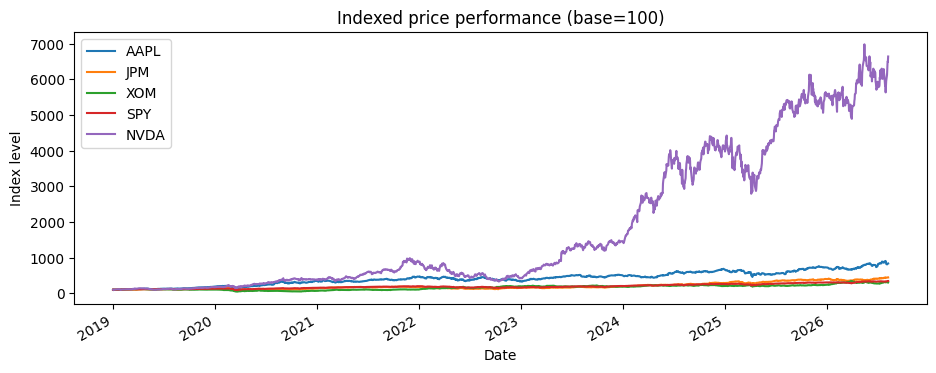

In [3]:
(prices / prices.iloc[0] * 100).plot(title='Indexed price performance (base=100)')
plt.ylabel('Index level')
plt.show()


In [4]:
log_returns = compute_log_returns(prices)
weights = equal_weights(list(prices.columns))
portfolio_returns = compute_portfolio_returns(log_returns, weights)
portfolio_value = compute_portfolio_value(portfolio_returns)

print('Weights:')
print(weights)
portfolio_returns.describe()


Weights:
AAPL   0.2000
JPM    0.2000
XOM    0.2000
SPY    0.2000
NVDA   0.2000
dtype: float64


count   1,909.0000
mean        0.0011
std         0.0154
min        -0.1439
25%        -0.0058
50%         0.0015
75%         0.0085
max         0.1145
Name: portfolio, dtype: float64

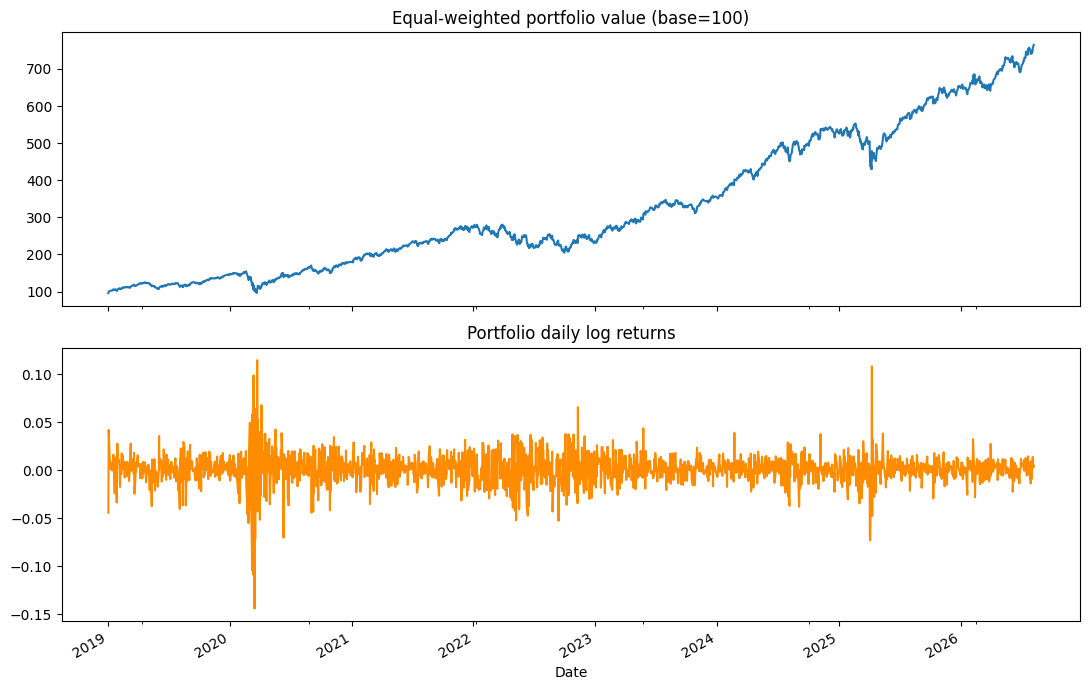

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
portfolio_value.plot(ax=axes[0], title='Equal-weighted portfolio value (base=100)')
portfolio_returns.plot(ax=axes[1], title='Portfolio daily log returns', color='darkorange')
plt.tight_layout()
plt.show()


## 2. Value-at-Risk

We compute 1-day VaR at 95% and 99% confidence with three methods:

- **Historical simulation** — the empirical quantile of realized returns. No distributional
  assumption, but entirely backward-looking.
- **Parametric (variance-covariance)** — assumes returns are Normally distributed;
  fast and analytically clean, but understates tail risk since real returns are fat-tailed.
- **Monte Carlo** — simulates thousands of return paths from a fitted Normal distribution
  and takes the empirical quantile of the simulated outcomes; extends naturally to more
  complex assumptions later (e.g. fat-tailed or correlated multi-asset simulation).


In [6]:
var_table = var_summary(portfolio_returns, confidences=[0.95, 0.99])
var_table_pct = var_table.copy()
display(var_table_pct.style.format('{:.2%}'))


,historical_var,parametric_var,monte_carlo_var
confidence,,,
0.950000,2.18%,2.42%,2.46%
0.990000,4.28%,3.47%,3.54%


In [7]:
notional = 1_000_000
display((var_table * notional).round(0).rename(columns=lambda c: c + '_$'))


,historical_var_$,parametric_var_$,monte_carlo_var_$
confidence,,,
0.9500,"21,813.0000","24,195.0000","24,645.0000"
0.9900,"42,776.0000","34,662.0000","35,391.0000"


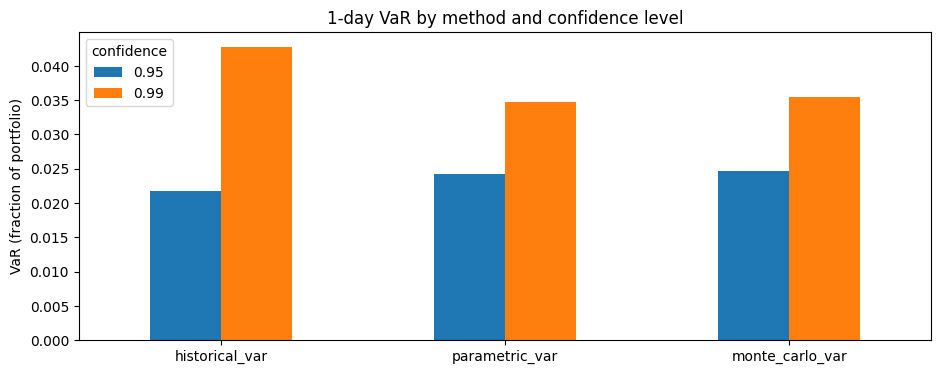

In [8]:
var_table.T.plot(kind='bar', title='1-day VaR by method and confidence level')
plt.ylabel('VaR (fraction of portfolio)')
plt.xticks(rotation=0)
plt.show()


**Observation:** Historical VaR at 99% is typically higher than the Normal-based parametric
estimate — a signature of fat tails (excess kurtosis) in real equity returns that the Normal
distribution understates. This is exactly why regulators (Basel III/FRTB) have pushed toward
Expected Shortfall and stressed-period calibration rather than relying on parametric VaR alone.


## 3. Expected Shortfall (CVaR)

In [9]:
es_table = es_summary(portfolio_returns, confidences=[0.95, 0.99])
display(es_table.style.format('{:.2%}'))


,historical_es,parametric_es,monte_carlo_es
confidence,,,
0.950000,3.66%,3.06%,3.11%
0.990000,6.29%,3.99%,4.08%


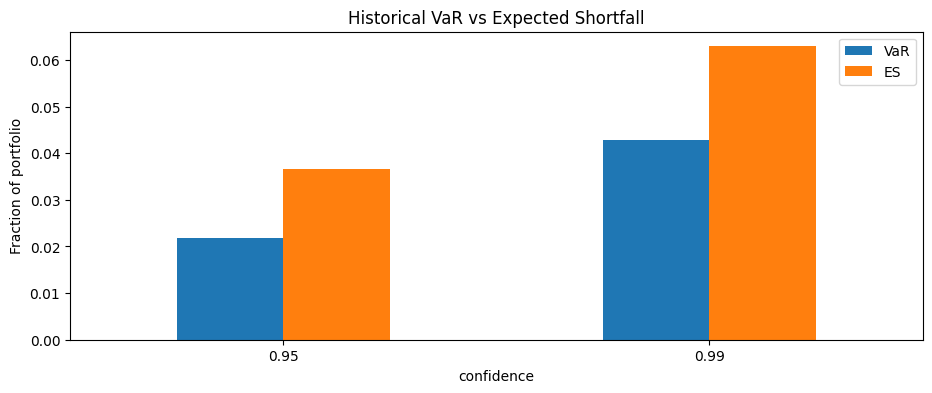

In [10]:
comparison = pd.concat([
    var_table['historical_var'].rename('VaR'),
    es_table['historical_es'].rename('ES'),
], axis=1)
comparison.plot(kind='bar', title='Historical VaR vs Expected Shortfall')
plt.ylabel('Fraction of portfolio')
plt.xticks(rotation=0)
plt.show()


ES is always $\geq$ VaR at the same confidence level by construction — it's the average
loss *given that* the VaR threshold was breached, so it captures how bad the tail actually is,
not just where it starts. This is why ES is the preferred metric under FRTB.


## 4. Stress Testing

Hypothetical, analyst-defined scenarios rather than purely historical/statistical estimates —
useful for tail events that may be under-represented in the sample.


In [11]:
print('Equity shock: all assets -15% simultaneously')
print(f"  Portfolio impact: {equity_shock(weights, -0.15):.2%} (${equity_shock(weights, -0.15) * notional:,.0f} on ${notional:,.0f})")

print('\nVolatility doubles (99% VaR/ES before vs after)')
vol_result = volatility_spike_var(portfolio_returns, multiplier=2.0, confidence=0.99)
for k, v in vol_result.items():
    print(f'  {k}: {v}')

print('\nCorrelation breakdown (contagion, all correlations -> 1.0)')
corr_result = correlation_breakdown(log_returns, weights)
for k, v in corr_result.items():
    print(f'  {k}: {v}')


Equity shock: all assets -15% simultaneously
  Portfolio impact: -15.00% ($-150,000 on $1,000,000)

Volatility doubles (99% VaR/ES before vs after)
  baseline_var: 0.034661817020356284
  shocked_var: 0.07038972978345952
  baseline_es: 0.03986610628174934
  shocked_es: 0.08079830830624563
  multiplier: 2.0

Correlation breakdown (contagion, all correlations -> 1.0)
  portfolio_vol_actual: 0.015357940728376202
  portfolio_vol_contagion: 0.02029445172615308
  vol_increase_pct: 0.321430528030096


In [12]:
stress_table = run_stress_tests(log_returns, portfolio_returns, weights, confidence=0.99)
stress_table


,scenario,metric,value
0,Equity shock: all assets -15%,Portfolio return,-0.1500
1,Volatility doubles,VaR 99% (baseline -> shocked),0.0357
2,"Correlation breakdown (contagion, rho=1)",Portfolio volatility increase,0.3214


**Observation:** the correlation breakdown scenario is the one most analysts underweight
intuitively — going from historical correlations to rho=1 across all five assets removes
essentially all diversification benefit and materially raises portfolio volatility, even though
no single asset's own volatility changed. This is the classic 'contagion' failure mode seen in
2008 and March 2020.


## 5. Regime Detection (2-State Markov Model)

We fit a 2-state Gaussian Hidden Markov Model (via Baum-Welch / EM) on rolling 21-day
annualized volatility of portfolio returns, classifying each day as **calm** or **volatile**
and estimating the day-to-day transition probabilities between the two regimes.


In [13]:
regimes, transmat, params = classify_regimes(portfolio_returns, window=21)

print(f"Mean annualized vol — calm: {params['mean_vol_calm']:.2%}, volatile: {params['mean_vol_volatile']:.2%}")
print('\nTransition matrix:')
display(params['transition_matrix'].style.format('{:.2%}'))

n_calm = (regimes['regime'] == 'calm').sum()
n_vol = (regimes['regime'] == 'volatile').sum()
print(f"\nDays calm: {n_calm} ({n_calm/len(regimes):.1%}), Days volatile: {n_vol} ({n_vol/len(regimes):.1%})")


Mean annualized vol — calm: 14.43%, volatile: 30.56%

Transition matrix:


,to_calm,to_volatile
from_calm,99.18%,0.82%
from_volatile,1.34%,98.66%



Days calm: 1125 (59.6%), Days volatile: 764 (40.4%)


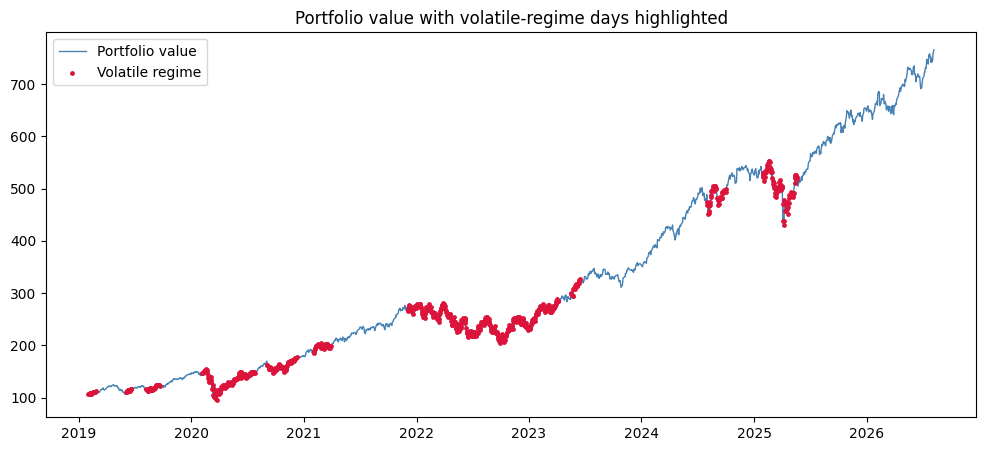

In [14]:
fig, ax = plt.subplots(figsize=(12, 5))
price_index = portfolio_value.reindex(regimes.index)
ax.plot(price_index.index, price_index.values, color='steelblue', label='Portfolio value', linewidth=1)

volatile_mask = regimes['regime'] == 'volatile'
ax.scatter(regimes.index[volatile_mask], price_index[volatile_mask], color='crimson', s=6, label='Volatile regime', zorder=3)

ax.set_title('Portfolio value with volatile-regime days highlighted')
ax.legend()
plt.show()


**Observation:** the volatile regime clusters tightly around known market stress episodes
(the Feb–Mar 2020 COVID crash, the 2022 rate-hike selloff), which is a good sanity check that
the unsupervised Markov model is picking up genuine regime shifts rather than noise. The high
diagonal transition probabilities (~0.98–0.99) confirm regimes are 'sticky' — once volatile,
markets tend to stay volatile for a while, consistent with volatility clustering (a well-known
stylized fact of financial returns).


## 6. VaR Backtesting (Kupiec Test)

We roll a 250-day historical VaR forecast forward (no look-ahead: each day's VaR is estimated
only from the prior 250 days) and count how often the realized loss exceeded the forecast VaR.
The Kupiec (1995) unconditional coverage test checks whether the observed breach rate is
statistically consistent with the model's stated confidence level.


In [15]:
bt = backtest_summary(portfolio_returns, confidence=0.95, window=250)
for k, v in bt['kupiec'].items():
    print(f'{k}: {v}')


n_observations: 1659
n_breaches: 87
expected_breaches: 82.95000000000007
observed_breach_rate: 0.05244122965641953
expected_breach_rate: 0.050000000000000044
lr_statistic: 0.20501402474951647
p_value: 0.6507037498898872
reject_at_5pct: False
interpretation: Model NOT rejected at 5% significance: breach rate is statistically consistent with the stated confidence level.


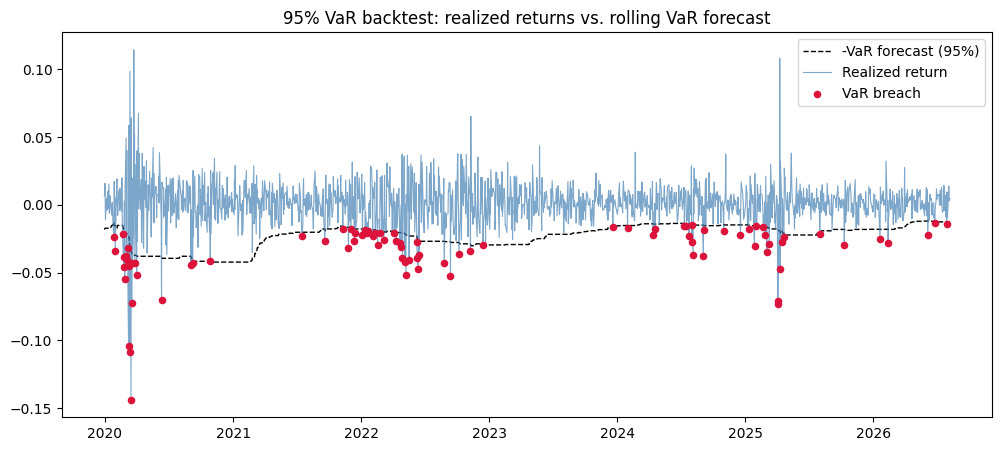

In [16]:
breaches = bt['breaches_df']
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(breaches.index, -breaches['var_forecast'], color='black', linestyle='--', label='-VaR forecast (95%)', linewidth=1)
ax.plot(breaches.index, breaches['realized_return'], color='steelblue', label='Realized return', linewidth=0.8, alpha=0.7)
breach_days = breaches[breaches['breach']]
ax.scatter(breach_days.index, breach_days['realized_return'], color='crimson', s=20, zorder=3, label='VaR breach')
ax.set_title('95% VaR backtest: realized returns vs. rolling VaR forecast')
ax.legend()
plt.show()


**Interpretation:** with a 95% VaR model, we expect roughly 5% of days to be breaches.
The Kupiec test's p-value tells us whether the observed breach rate is close enough to that
5% target to not reject the model at conventional significance. A model with too *few* breaches
is overly conservative (ties up excess capital); too *many* breaches means the risk model is
understating true risk — both are failure modes regulators specifically test for.


## Summary

This notebook walked through a full market-risk workflow on a real 5-asset equity portfolio:
VaR via three complementary methods, Expected Shortfall for tail severity, scenario-based
stress testing for contagion/vol-spike risk not captured historically, unsupervised regime
detection via a Markov model, and out-of-sample backtesting to validate the VaR model itself.
The companion Streamlit dashboard (`app/dashboard.py`) makes all of this interactively
explorable with configurable tickers, date ranges, and weights.
